In [3]:
# Ejecutar programas externos
import subprocess  
'''
Count interables like lists, 
It could be used this way: Counter to investigate how frequently 
different Agencia_ID values appear in a sample
'''
from collections import Counter
from pathlib import Path
import cv2 as cv
import matplotlib.pyplot as plt
import pandas as pd 
import numpy as np

In [4]:
#plt.rcParams["figure.dpi"] = 80 ( Imagenes demasiado pesadas, NUNCA usar esto)
np.random.seed(42)
#No poner el caracter '/' aqui, ya que ira a la raiz de C:\
DATOS = Path("../data/raw") #usar r"path" si es que necesitas poner el path completo, aqui no pero

print("Dataset Listo en: ", DATOS.resolve())
print("OpenCV:", cv.__version__, "| Numpy:", np.__version__ )

Dataset Listo en:  C:\Users\alexi\Desktop\Personal\Proyecto_CV\Project_Active\data\raw
OpenCV: 4.11.0 | Numpy: 1.26.4


Ref C:\Users\alexi\Desktop\Personal\Proyecto_CV\Project_Active\data\raw\producto_antoni\antoni1.jpg


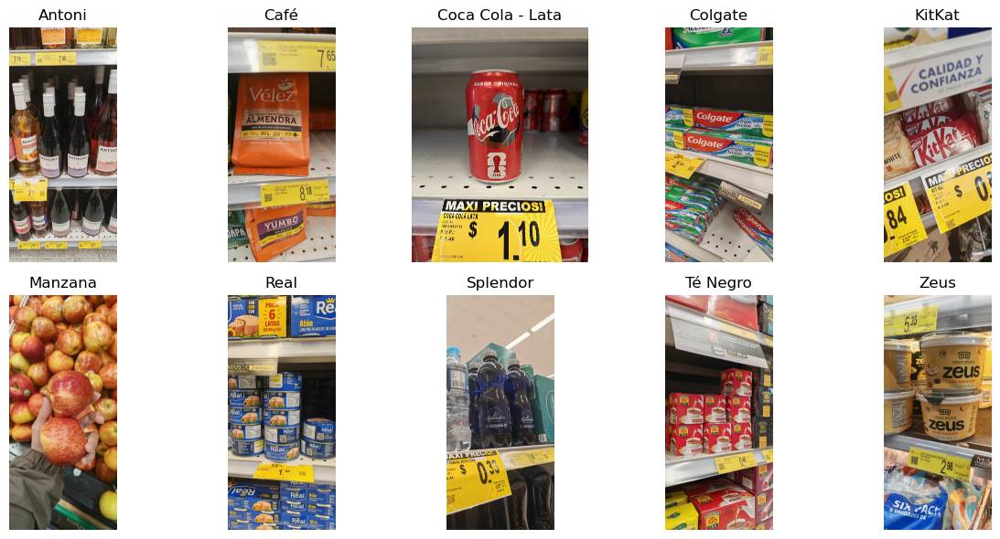

In [5]:
#algo importante aqui es:
#cuando se carga una imagen con cv.imread() se devuelve un np.ndarray
#numpy array, entonces esto es lo que estas viendo dentro del metodo
#mostrar, atributos como .dtype y .ndim pertenece un array numpy.
#ndim: Numero de dimensiones | dtype: np.uint8 o np.float32, etc | 

def leer_rgb(ruta):
    #leer en RGB
    return cv.cvtColor(cv.imread(str(ruta)), cv.COLOR_BGR2RGB)

def mostrar(imagenes, titulos, cmap=None, ancho=2.5, filas=2, columnas=5):
    fig, axes = plt.subplots(filas, columnas, figsize=(ancho*5, ancho*2.4))
    for ax, im, tit in zip(np.atleast_1d(axes).ravel(), imagenes, titulos):
        if im.ndim == 2:
            fijo = im.dtype == np.uint8
            ax.imshow(im, cmap=cmap or "gray", vmin=0 if fijo else None, vmax=255 if fijo else None)
        else:
            ax.imshow(im)
        ax.set_title(tit, fontsize=12)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

        
TRAIN = DATOS # por ahora todas las imagenes son de train
#Vamos con los 10 productos
print("Ref", (TRAIN / "producto_antoni/antoni1.jpg").resolve())

ANTONI = leer_rgb(TRAIN / "producto_antoni/antoni1.jpg")
CAFE = leer_rgb(TRAIN / "producto_cafe/cafe1.jpg")
COCACOLA = leer_rgb(TRAIN / "producto_cocacola/cocacola1.jpg") #Este es el unico que tiene mas de carpeta dentro de otra
COLGATE = leer_rgb(TRAIN / "producto_colgate/colgate1.jpg")
KITKAT = leer_rgb(TRAIN / "producto_kitkat/kitkat1.jpg")
MANZANA = leer_rgb(TRAIN / "producto_manzana/manzana29.jpg")
REAL = leer_rgb(TRAIN / "producto_real/real1.jpg")
SPLENDOR = leer_rgb(TRAIN / "producto_splendor/splendor1.jpg")
TENEGRO = leer_rgb(TRAIN / "producto_tenegro/tenegro1.jpg")
ZEUS = leer_rgb(TRAIN / "producto_zeus/zeus1.jpg")

mostrar(
    [ANTONI, CAFE, COCACOLA, COLGATE, KITKAT, MANZANA, REAL, SPLENDOR, TENEGRO, ZEUS],
    ["Antoni", "Café", "Coca Cola - Lata", "Colgate", "KitKat", "Manzana", "Real", "Splendor", "Té Negro", "Zeus"], 
    None, 2.5,2,5)

In [6]:
#vision clasica: Reglas y geometria --> Machine learning: con caracteristicas hechas a mano --> Deep learning: CNN que aprende 
#sus propias caracteristicas --> Transformers y modelos multimodales
''' Muy bien entonces ahora vamos distribucion de clases''' 
#Funny enough, when you spend time on something, you actually learn, who would have thought
RAIZ = Path("../data/raw")
FORMATOS_FOTOS = ['.jpg']#Por ahora solo se usaran .jpg (transformar otras fotos a este formato)

lista = [] 
for carpeta in sorted(RAIZ.iterdir()):
    if not carpeta.is_dir():
        continue
    for img in sorted(carpeta.iterdir()):
        if img.suffix.lower() in FORMATOS_FOTOS:
            #print(img)
            lista.append({"clase": carpeta.name, "ruta": str(img)})

df = pd.DataFrame(lista) 
df["clase_id"] = df["clase"].astype("category").cat.codes 
'''
Path atributos: 
img.name       # 'imagen.JPG'
img.stem       # 'imagen'
img.suffix     # '.JPG'
img.parent     # 'mis_fotos/cocacola'
img.suffixes   # ['.JPG']
'''
#accesor de pandas

"\nPath atributos: \nimg.name       # 'imagen.JPG'\nimg.stem       # 'imagen'\nimg.suffix     # '.JPG'\nimg.parent     # 'mis_fotos/cocacola'\nimg.suffixes   # ['.JPG']\n"

In [7]:
df.head()

,clase,ruta,clase_id
0,producto_antoni,..\data\raw\producto_antoni\antoni1.jpg,0
1,producto_antoni,..\data\raw\producto_antoni\antoni10.jpg,0
2,producto_antoni,..\data\raw\producto_antoni\antoni11.jpg,0
3,producto_antoni,..\data\raw\producto_antoni\antoni12.jpg,0
4,producto_antoni,..\data\raw\producto_antoni\antoni13.jpg,0


In [8]:
from sklearn.model_selection import train_test_split 

train, test = train_test_split(df, test_size= 0.2, stratify=df['clase'], random_state=42) 

#Aqui usar .assign() en vez de usar cosas como train['split'] = 'train', se usa
#Ya que assign retorna un nuevo dataframe en vez de cambiar el original 
df = pd.concat([train.assign(split='train'),test.assign(split='test') ],ignore_index=True)

In [9]:
df.head(10)

,clase,ruta,clase_id,split
0,producto_tenegro,..\data\raw\producto_tenegro\tenegro59.jpg,8,train
1,producto_zeus,..\data\raw\producto_zeus\zeus46.jpg,9,train
2,producto_cafe,..\data\raw\producto_cafe\cafe38.jpg,1,train
3,producto_colgate,..\data\raw\producto_colgate\colgate36.jpg,3,train
4,producto_splendor,..\data\raw\producto_splendor\splendor32.jpg,7,train
5,producto_splendor,..\data\raw\producto_splendor\splendor21.jpg,7,train
6,producto_splendor,..\data\raw\producto_splendor\splendor55.jpg,7,train
7,producto_colgate,..\data\raw\producto_colgate\colgate42.jpg,3,train
8,producto_antoni,..\data\raw\producto_antoni\antoni31.jpg,0,train
9,producto_tenegro,..\data\raw\producto_tenegro\tenegro90.jpg,8,train


clase
producto_cocacola     8
producto_kitkat      20
producto_manzana     33
producto_cafe        47
producto_real        52
producto_splendor    64
producto_zeus        68
producto_colgate     72
producto_tenegro     92
producto_antoni      94
Name: count, dtype: int64


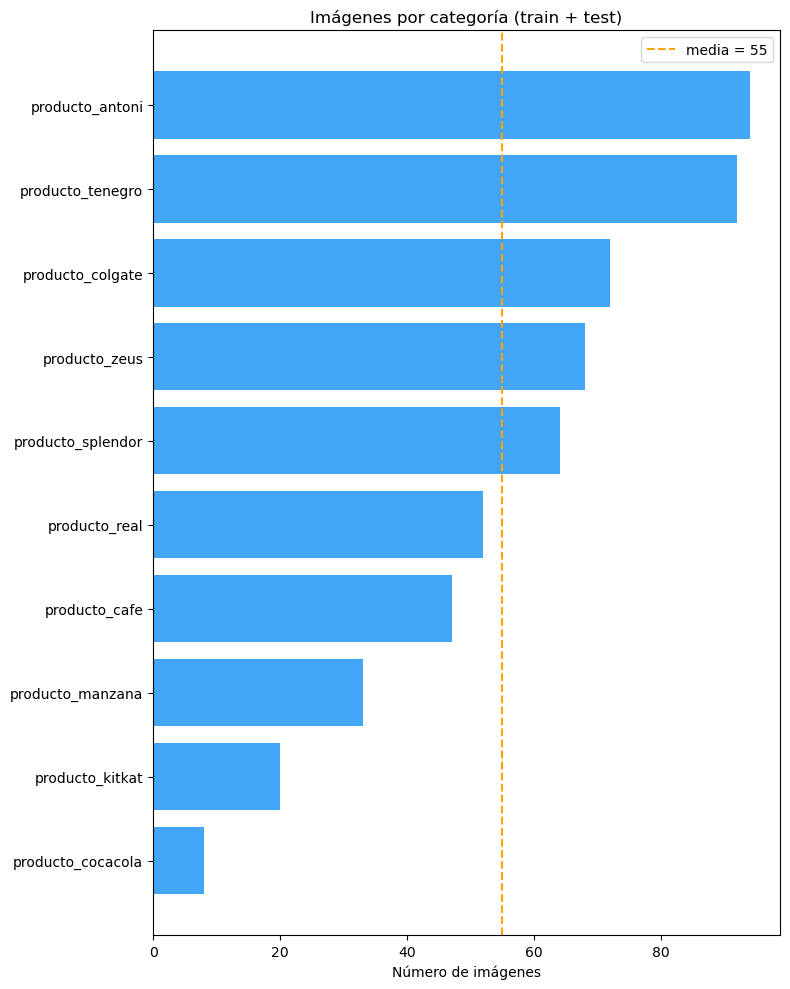

Mínimo: 8 (producto_cocacola)  |  Máximo: 94 (producto_antoni)
Razón de desbalance máx/mín: 11.8x


In [10]:
conteo = df["clase"].value_counts().sort_values()
print(conteo)
plt.figure(figsize=(8, 10))
plt.barh(conteo.index, conteo.values, color="#42A5F5")
plt.axvline(conteo.mean(), color="orange", ls="--", label=f"media = {conteo.mean():.0f}")
plt.title("Imágenes por categoría (train + test)")
plt.xlabel("Número de imágenes")
plt.legend()
plt.tight_layout()
plt.show()
print(f"Mínimo: {conteo.min()} ({conteo.idxmin()})  |  Máximo: {conteo.max()} ({conteo.idxmax()})")
print(f"Razón de desbalance máx/mín: {conteo.max() / conteo.min():.1f}x")

In [11]:
print(df['split'].value_counts()) 
#En base a esto solo se seleccionaran 100 de train

split
train    440
test     110
Name: count, dtype: int64


In [12]:
'''
formas.most_common(1)[0]
      │           │   │
      │           │   └── Index [0]: Grab the 1st element of the resulting list
      │           └────── Argument (1): "Return a list with a length of 1"
      └────────────────── Method call on the Counter
'''

'\nformas.most_common(1)[0]\n      │           │   │\n      │           │   └── Index [0]: Grab the 1st element of the resulting list\n      │           └────── Argument (1): "Return a list with a length of 1"\n      └────────────────── Method call on the Counter\n'

Formas (alto, ancho, canales) en una muestra de 300 imágenes:
 (4096, 1872, 3): 81
 (4032, 3024, 3): 7
 (3024, 4032, 3): 5
 (2360, 1080, 3): 3
 (5712, 4284, 3): 2
 (4284, 5712, 3): 1
 (4000, 1832, 3): 1


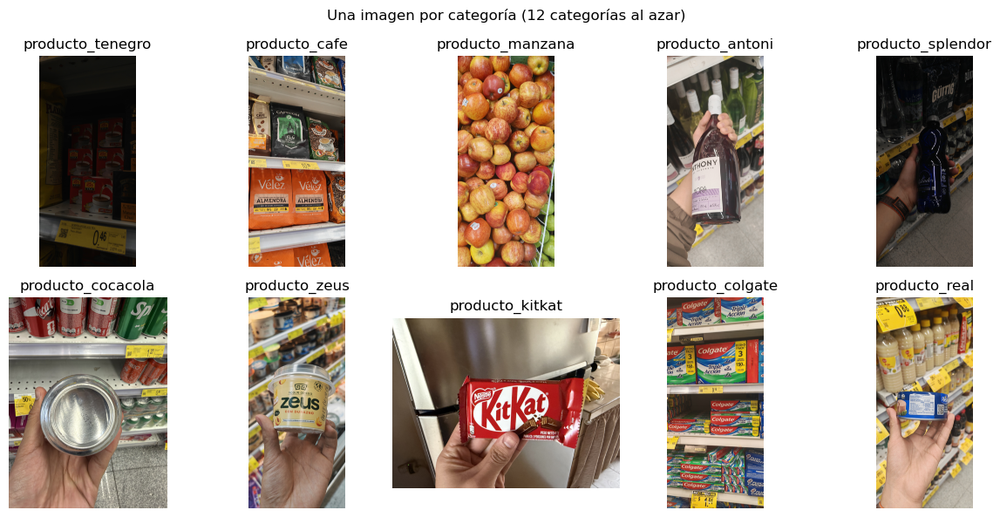

In [13]:

muestra = df[df["split"] == "train"].sample(100, random_state=42)
formas = Counter(cv.imread(str(r)).shape for r in muestra["ruta"])

#print(formas.most_common())
#Conocer las dimensiones de las diferentes fotos\]
print("Formas (alto, ancho, canales) en una muestra de 300 imágenes:")
for forma, n in formas.most_common():
    print(f" {forma}: {n}")

ejemplos = df[df["split"] == "train"].groupby("clase").first().sample(10,random_state=42) #first() Es el que realiza
#El muestreo de la primera instancia por clase (Selecciona el primero y despues pasa a siguiente clase, sample extrae 
#10 valores del dataframe que hizo first()
figs, axes = plt.subplots(2,5,figsize=(5*2.5,2.4*2.5))
for axis, (clase, fila) in zip(axes.ravel(), ejemplos.iterrows()): #remember ejemplos holds the df but now the index
    #is clase, this is why iterrows tuples make sense here, and also why it doesn't use the method we made 
        axis.imshow(leer_rgb(fila['ruta']))
        axis.set_title(clase)
        axis.axis('off')
plt.suptitle("Una imagen por categoría (12 categorías al azar)")
plt.tight_layout()
plt.show()

In [14]:
ejemplos.head(10) #Ignorar eso, solo referencia para enteder lo de arriba

,ruta,clase_id,split
clase,,,
producto_tenegro,..\data\raw\producto_tenegro\tenegro59.jpg,8,train
producto_cafe,..\data\raw\producto_cafe\cafe38.jpg,1,train
producto_manzana,..\data\raw\producto_manzana\manzana26.jpg,5,train
producto_antoni,..\data\raw\producto_antoni\antoni31.jpg,0,train
producto_splendor,..\data\raw\producto_splendor\splendor32.jpg,7,train
producto_cocacola,..\data\raw\producto_cocacola\cocacola6.jpg,2,train
producto_zeus,..\data\raw\producto_zeus\zeus46.jpg,9,train
producto_kitkat,..\data\raw\producto_kitkat\kitkat11.jpg,4,train
producto_colgate,..\data\raw\producto_colgate\colgate36.jpg,3,train


In [15]:
#ignore this
print(ejemplos.iterrows())
for(clase,fila) in ejemplos.iterrows():
    print(clase,'\n-------\n',fila, '--l-----\n')

<generator object DataFrame.iterrows at 0x00000289904349D0>
producto_tenegro 
-------
 ruta        ..\data\raw\producto_tenegro\tenegro59.jpg
clase_id                                             8
split                                            train
Name: producto_tenegro, dtype: object --l-----

producto_cafe 
-------
 ruta        ..\data\raw\producto_cafe\cafe38.jpg
clase_id                                       1
split                                      train
Name: producto_cafe, dtype: object --l-----

producto_manzana 
-------
 ruta        ..\data\raw\producto_manzana\manzana26.jpg
clase_id                                             5
split                                            train
Name: producto_manzana, dtype: object --l-----

producto_antoni 
-------
 ruta        ..\data\raw\producto_antoni\antoni31.jpg
clase_id                                           0
split                                          train
Name: producto_antoni, dtype: object --l-----

producto_spl

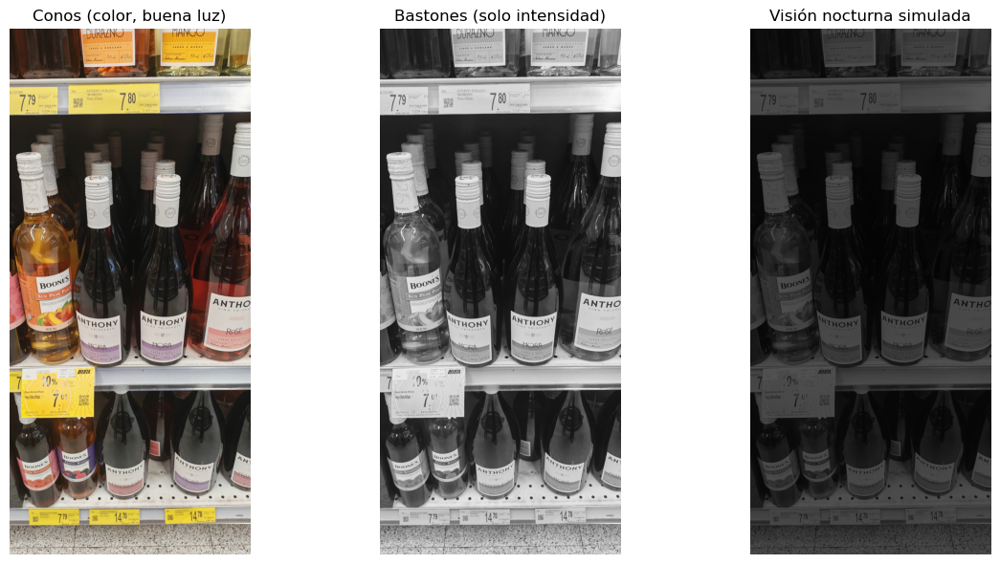

In [16]:
# Los bastones solo perciben intensidad: equivale a quedarnos con la luminancia de la imagen
bastones = cv.cvtColor(ANTONI, cv.COLOR_RGB2GRAY)
# Simulamos visión nocturna: con poca luz solo trabajan los bastones y todo se ve más oscuro
nocturna = (bastones * 0.35).astype(np.uint8)
mostrar([ANTONI, bastones, nocturna],
        ["Conos (color, buena luz)", "Bastones (solo intensidad)", "Visión nocturna simulada"],None, 2.5, 1, 3)

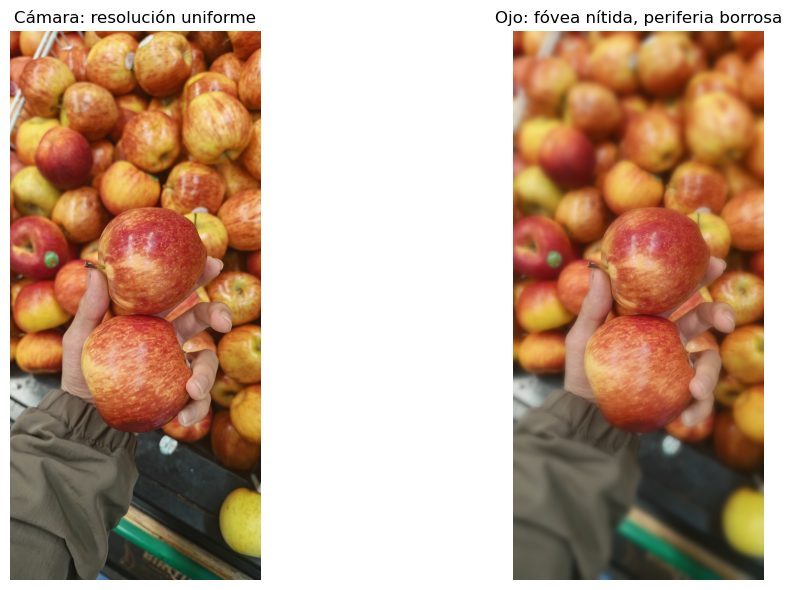

In [17]:
h, w = MANZANA.shape[:2]
yy, xx = np.mgrid[:h, :w]
distancia = np.sqrt((yy - h / 2) ** 2 + (xx - w / 2) ** 2) / (0.5 * np.hypot(h, w))
peso = np.clip(distancia * 1.6, 0, 1)[..., None]  # 0 en el centro, 1 en la periferia

periferia = cv.GaussianBlur(MANZANA, (0, 0), sigmaX=21)
foveada = (MANZANA * (1 - peso) + periferia * peso).astype(np.uint8)
mostrar([MANZANA, foveada], ["Cámara: resolución uniforme", "Ojo: fóvea nítida, periferia borrosa"], None, 2.5, 1,2)

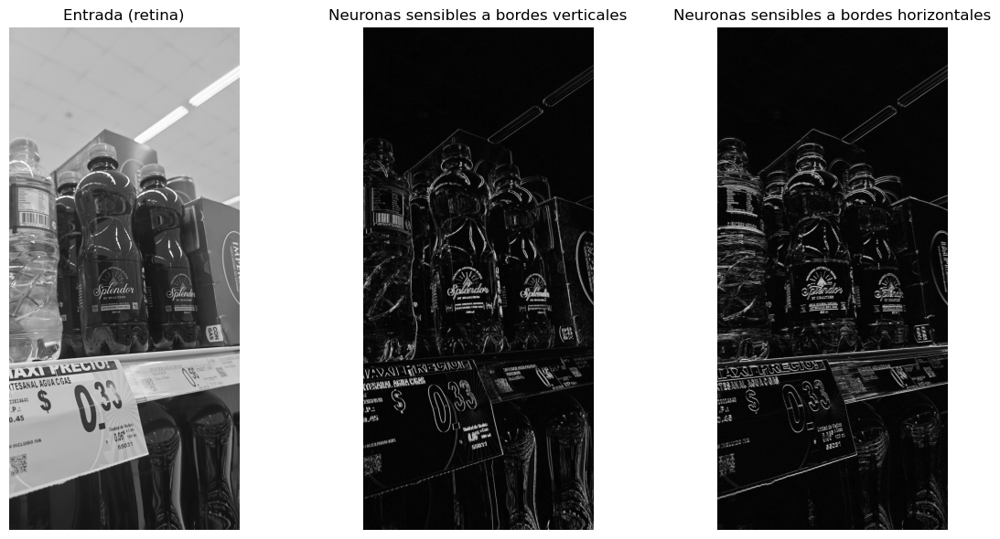

In [18]:
gris = cv.cvtColor(SPLENDOR, cv.COLOR_RGB2GRAY)
bordes_verticales = np.abs(cv.Sobel(gris, cv.CV_64F, 1, 0, ksize=3))
bordes_horizontales = np.abs(cv.Sobel(gris, cv.CV_64F, 0, 1, ksize=3))
# Escalamos al percentil 99 para que unos pocos bordes muy fuertes no oscurezcan el resto
bordes_verticales = np.clip(bordes_verticales / np.percentile(bordes_verticales, 99), 0, 1)
bordes_horizontales = np.clip(bordes_horizontales / np.percentile(bordes_horizontales, 99), 0, 1)
mostrar([gris, bordes_verticales, bordes_horizontales],
        ["Entrada (retina)", "Neuronas sensibles a bordes verticales", "Neuronas sensibles a bordes horizontales"],
        "gray", 2.5, 1, 3)

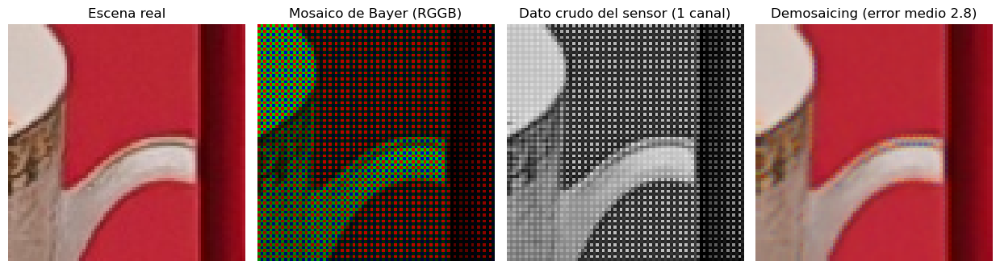

Forma del dato crudo: (80, 80) | Forma reconstruida: (80, 80, 3)


In [41]:
recorte = TENEGRO[2000:2080, 600:680]  # recorte de 80x80 para ver el mosaico
h, w = recorte.shape[:2]

# Lo que mide el sensor: una sola matriz 2D, cada píxel con un único canal según el patrón RGGB
crudo = np.zeros((h, w), np.uint8)
crudo[0::2, 0::2] = recorte[0::2, 0::2, 0]  # R
crudo[0::2, 1::2] = recorte[0::2, 1::2, 1]  # G
crudo[1::2, 0::2] = recorte[1::2, 0::2, 1]  # G
crudo[1::2, 1::2] = recorte[1::2, 1::2, 2]  # B

# Visualización del mosaico: cada píxel pintado del color de su filtro
mosaico = np.zeros_like(recorte)
mosaico[0::2, 0::2, 0] = crudo[0::2, 0::2]
mosaico[0::2, 1::2, 1] = crudo[0::2, 1::2]
mosaico[1::2, 0::2, 1] = crudo[1::2, 0::2]
mosaico[1::2, 1::2, 2] = crudo[1::2, 1::2]

reconstruida = cv.cvtColor(crudo, cv.COLOR_BayerRGGB2RGB)  # demosaicing
error = np.abs(reconstruida.astype(int) - recorte.astype(int)).mean()

mostrar([recorte, mosaico, crudo, reconstruida],
        ["Escena real", "Mosaico de Bayer (RGGB)", "Dato crudo del sensor (1 canal)",
         f"Demosaicing (error medio {error:.1f})"],"gray", 2.5, 1, 4)
print("Forma del dato crudo:", crudo.shape, "| Forma reconstruida:", reconstruida.shape)

Forma: (4096, 1872, 3) → (alto, ancho, canales)
Tipo de dato: uint8 → enteros sin signo de 8 bits, rango 0 a 255
Número de valores: 23003136 = 4096 × 1872 × 3

Píxel RGB en (fila=1800, col=1000): [213 129  82]

Parche 15x15 en escala de grises (una tabla de datos de 15 filas y 15 columnas):
[[149 148 143 148 159 165 165 160 153 150 151 154 147 144 153]
 [150 152 154 163 169 167 167 169 158 155 150 149 151 153 163]
 [154 163 167 165 160 156 161 168 165 154 160 164 163 170 179]
 [157 163 159 151 143 141 152 163 164 146 160 173 174 181 177]
 [156 150 142 144 142 137 147 162 147 139 155 171 179 176 151]
 [166 161 154 155 152 146 151 160 145 146 166 176 171 164 144]
 [182 177 165 157 152 149 151 152 155 155 170 175 163 163 162]
 [185 168 145 137 138 139 141 141 147 153 161 169 174 177 172]
 [174 163 139 143 145 141 141 134 136 142 149 154 169 172 158]
 [172 171 151 153 155 150 148 142 143 142 153 159 159 149 154]
 [174 172 148 145 152 154 152 150 151 158 165 164 153 148 161]
 [170 161 142 1

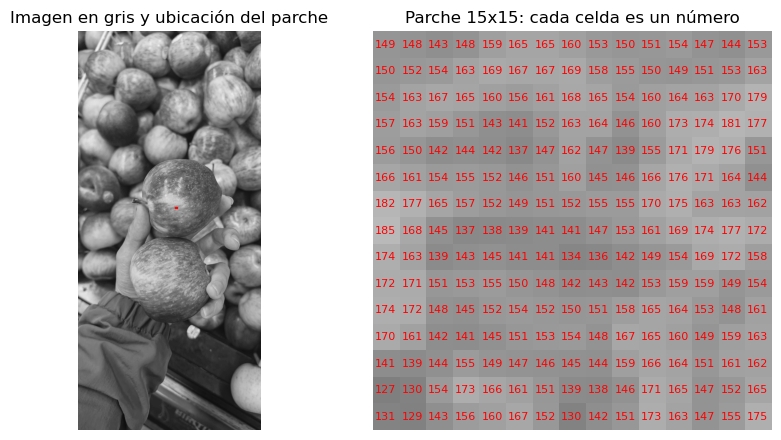

In [55]:
print("Forma:", MANZANA.shape, "→ (alto, ancho, canales)")
print("Tipo de dato:", MANZANA.dtype, "→ enteros sin signo de 8 bits, rango",
      MANZANA.min(), "a", MANZANA.max())
print("Número de valores:", MANZANA.size, "=", " × ".join(map(str, MANZANA.shape)))

gris = cv.cvtColor(MANZANA, cv.COLOR_RGB2GRAY)
fila, col = 1800, 1000
parche = gris[fila:fila + 15, col:col + 15]
print(f"\nPíxel RGB en (fila={fila}, col={col}):", MANZANA[fila, col])
print("\nParche 15x15 en escala de grises (una tabla de datos de 15 filas y 15 columnas):")
print(parche)

fig, ejes = plt.subplots(1, 2, figsize=(9, 4.5))
ejes[0].imshow(gris, cmap="gray")
ejes[0].add_patch(plt.Rectangle((col, fila), 15, 15, edgecolor="red", fill=False, lw=1))
ejes[0].set_title("Imagen en gris y ubicación del parche")
ejes[1].imshow(parche, cmap="gray", vmin=0, vmax=255)
for (i, j), v in np.ndenumerate(parche):
    ejes[1].text(j, i, v, ha="center", va="center", color="red", fontsize=8)
ejes[1].set_title("Parche 15x15: cada celda es un número")
for e in ejes:
    e.axis("off")
plt.tight_layout()
plt.show()

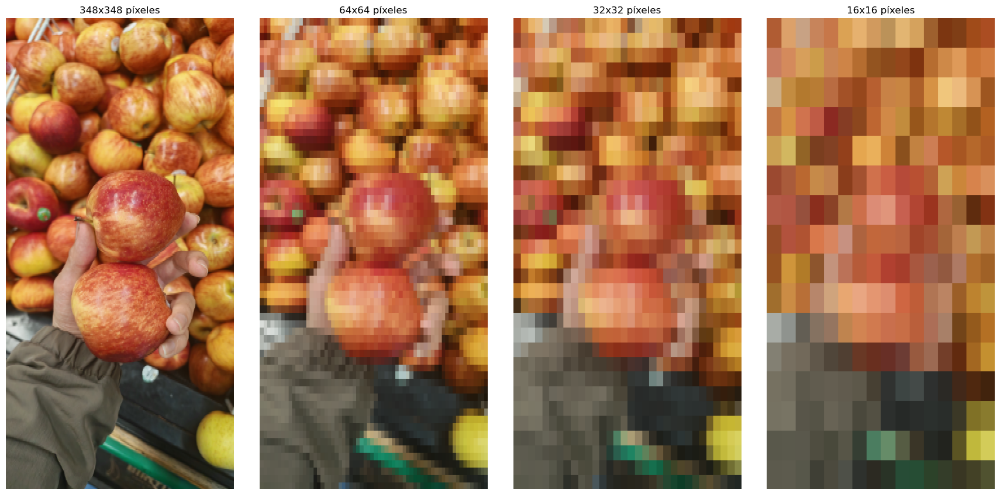

In [62]:
resoluciones = [348, 64, 32, 16]
versiones = []
for r in resoluciones:
    pequena = cv.resize(MANZANA, (r, r), interpolation=cv.INTER_AREA)
    # Volvemos sin interpolar, para ver los píxeles como bloques
    versiones.append(cv.resize(pequena, (338, 700), interpolation=cv.INTER_NEAREST))
mostrar(versiones, [f"{r}x{r} píxeles" for r in resoluciones], None, 3.5, 1, 4)

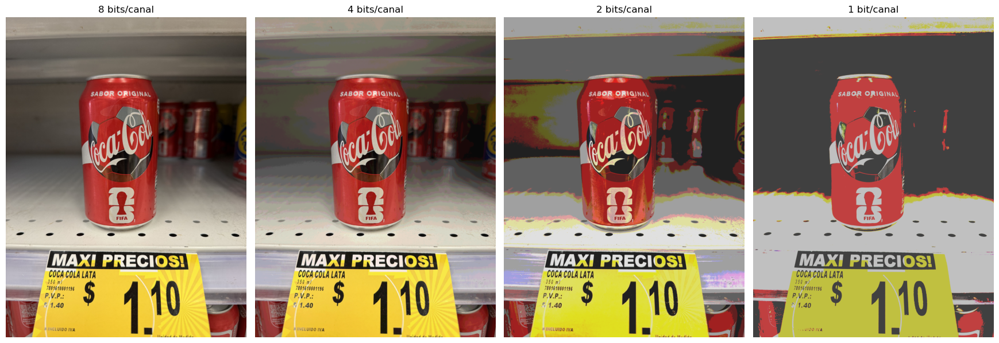

,bits por canal,niveles por canal,colores posibles,colores usados,tamaño en memoria (KB)
0,8,256,16777216,299342,71690.1
1,4,16,4096,873,35845.0
2,2,4,64,36,17922.5
3,1,2,8,8,8961.3


In [65]:
def cuantificar(img, bits):
    niveles = 2 ** bits
    paso = 256 // niveles
    # Cada valor se lleva al centro de su intervalo: 256 niveles → 'niveles' niveles
    return (img // paso * paso + paso // 2).astype(np.uint8)


filas = []
for bits in [8, 4, 2, 1]:
    q = cuantificar(COCACOLA, bits)
    colores = len(np.unique(q.reshape(-1, 3), axis=0))
    filas.append({"bits por canal": bits, "niveles por canal": 2 ** bits,
                  "colores posibles": (2 ** bits) ** 3, "colores usados": colores,
                  "tamaño en memoria (KB)": COCACOLA.shape[0] * COCACOLA.shape[1] * 3 * bits / 8 / 1024})
mostrar([cuantificar(COCACOLA, b) for b in [8, 4, 2, 1]],
        ["8 bits/canal", "4 bits/canal", "2 bits/canal", "1 bit/canal"], None, 3.5, 1,4)
pd.DataFrame(filas).round(1)

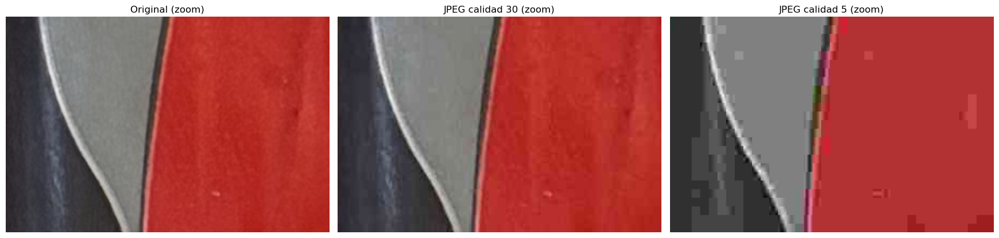

,formato,tamaño (KB),error medio por píxel
0,BMP,71690.12,0.00
1,PNG,23704.47,0.00
2,JPEG calidad 90,3310.55,0.70
3,JPEG calidad 30,728.11,2.27
4,JPEG calidad 5,418.82,8.31


In [72]:
bgr = cv.cvtColor(COCACOLA, cv.COLOR_RGB2BGR)
filas, decodificadas = [], []
for nombre, ext, params in [("BMP", ".bmp", []), ("PNG", ".png", []),
                            ("JPEG calidad 90", ".jpg", [cv.IMWRITE_JPEG_QUALITY, 90]),
                            ("JPEG calidad 30", ".jpg", [cv.IMWRITE_JPEG_QUALITY, 30]),
                            ("JPEG calidad 5", ".jpg", [cv.IMWRITE_JPEG_QUALITY, 5])]:
    ok, buffer = cv.imencode(ext, bgr, params)
    recuperada = cv.cvtColor(cv.imdecode(buffer, cv.IMREAD_COLOR), cv.COLOR_BGR2RGB)
    decodificadas.append((nombre, recuperada))
    filas.append({"formato": nombre, "tamaño (KB)": buffer.size / 1024,
                  "error medio por píxel": np.abs(recuperada.astype(int) - COCACOLA.astype(int)).mean()})

zoom = (slice(2000, 2200), slice(1500, 1800))
mostrar([COCACOLA[zoom], decodificadas[3][1][zoom], decodificadas[4][1][zoom]],
        ["Original (zoom)", "JPEG calidad 30 (zoom)", "JPEG calidad 5 (zoom)"],None, 3.5, 1,3)
pd.DataFrame(filas).round(2)

Diferencia máxima fórmula manual vs OpenCV: 1
Diferencia media promedio simple vs ponderado: 7.0


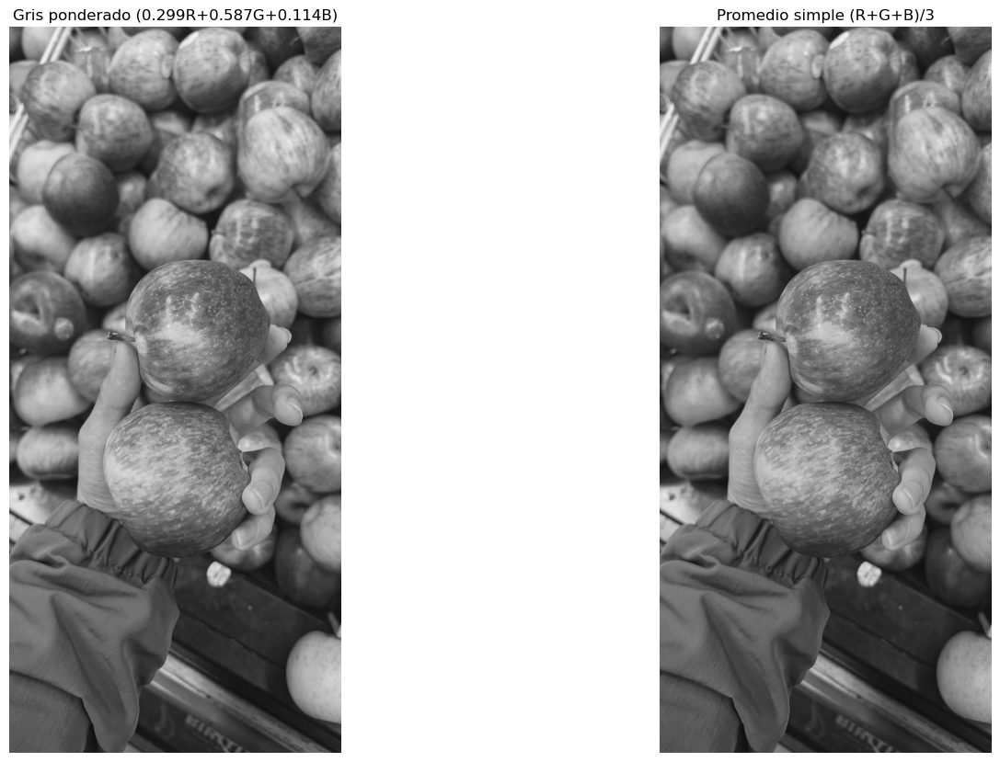

In [78]:
R, G, B = [MANZANA[..., i].astype(float) for i in range(3)]
gris_manual = (0.299 * R + 0.587 * G + 0.114 * B).round().astype(np.uint8)
gris_opencv = cv.cvtColor(MANZANA, cv.COLOR_RGB2GRAY)
gris_promedio = ((R + G + B) / 3).round().astype(np.uint8)

print("Diferencia máxima fórmula manual vs OpenCV:",
      np.abs(gris_manual.astype(int) - gris_opencv.astype(int)).max())
print("Diferencia media promedio simple vs ponderado:",
      np.abs(gris_promedio.astype(int) - gris_opencv.astype(int)).mean().round(1))
mostrar([gris_opencv, gris_promedio], ["Gris ponderado (0.299R+0.587G+0.114B)", "Promedio simple (R+G+B)/3"],
        "gray",3.5, 1,2)

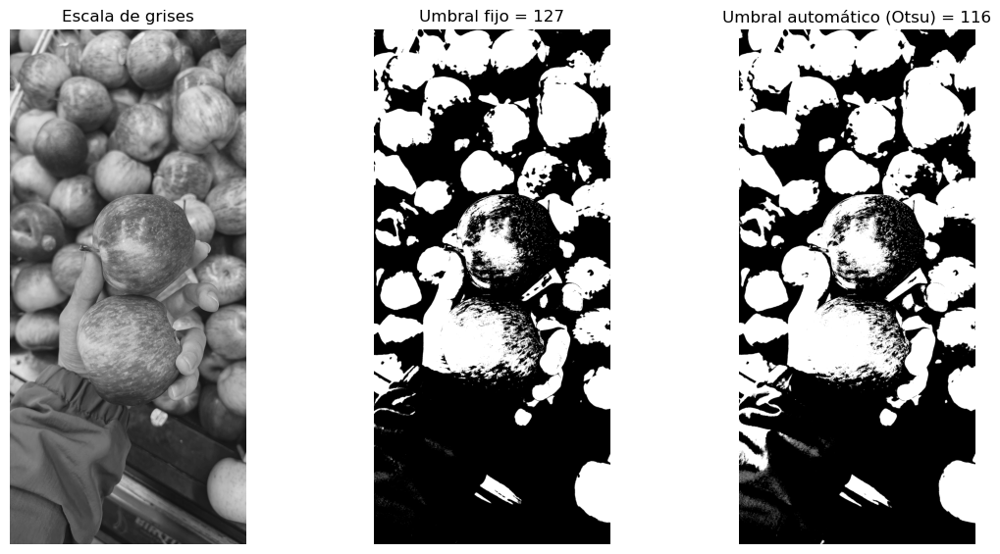

Valores únicos en la imagen binaria: [  0 255]


In [82]:
gris = cv.cvtColor(MANZANA, cv.COLOR_RGB2GRAY)
_, binaria_127 = cv.threshold(gris, 127, 255, cv.THRESH_BINARY)
umbral_otsu, binaria_otsu = cv.threshold(gris, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
mostrar([gris, binaria_127, binaria_otsu],
        ["Escala de grises", "Umbral fijo = 127", f"Umbral automático (Otsu) = {umbral_otsu:.0f}"], "gray", 2.4, 1,3)
print("Valores únicos en la imagen binaria:", np.unique(binaria_127))

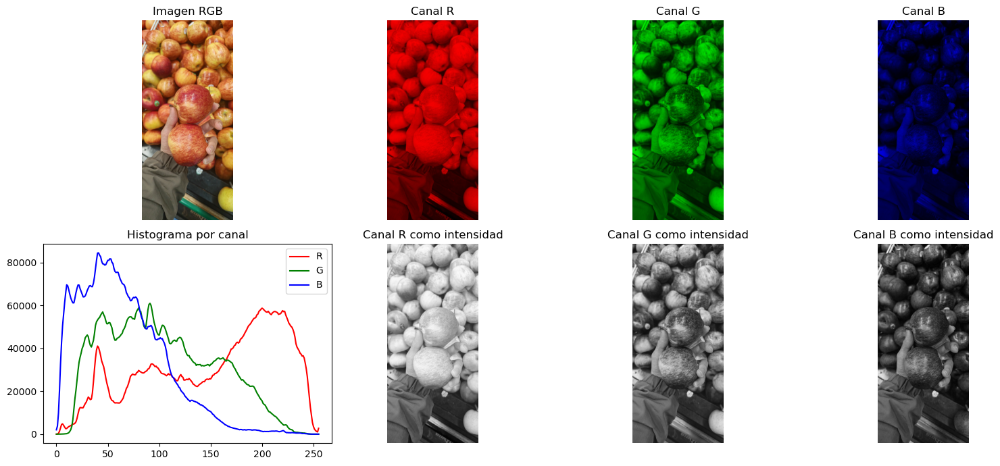

In [84]:
fig, ejes = plt.subplots(2, 4, figsize=(16, 7))
ejes[0, 0].imshow(MANZANA)
ejes[0, 0].set_title("Imagen RGB")
colores = ["red", "green", "blue"]
for i, (nombre, color) in enumerate(zip(["R", "G", "B"], colores)):
    canal = np.zeros_like(MANZANA)
    canal[..., i] = MANZANA[..., i]
    ejes[0, i + 1].imshow(canal)
    ejes[0, i + 1].set_title(f"Canal {nombre}")
    ejes[1, i + 1].imshow(MANZANA[..., i], cmap="gray")
    ejes[1, i + 1].set_title(f"Canal {nombre} como intensidad")
    hist = cv.calcHist([MANZANA], [i], None, [256], [0, 256]).ravel()
    ejes[1, 0].plot(hist, color=color, label=nombre)
ejes[1, 0].set_title("Histograma por canal")
ejes[1, 0].legend()
for e in list(ejes[0]) + list(ejes[1, 1:]):
    e.axis("off")
plt.tight_layout()
plt.show()

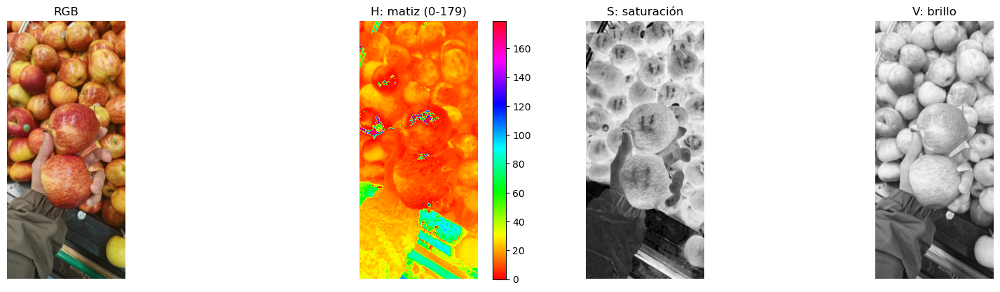

In [85]:
hsv = cv.cvtColor(MANZANA, cv.COLOR_RGB2HSV)
fig, ejes = plt.subplots(1, 4, figsize=(17, 4.2))
ejes[0].imshow(MANZANA)
ejes[0].set_title("RGB")
mapa = ejes[1].imshow(hsv[..., 0], cmap="hsv", vmin=0, vmax=179)
ejes[1].set_title("H: matiz (0-179)")
plt.colorbar(mapa, ax=ejes[1], fraction=0.046)
ejes[2].imshow(hsv[..., 1], cmap="gray")
ejes[2].set_title("S: saturación")
ejes[3].imshow(hsv[..., 2], cmap="gray")
ejes[3].set_title("V: brillo")
for e in ejes:
    e.axis("off")
plt.tight_layout()
plt.show()

In [88]:
oscura = (MANZANA.astype(float) * 0.45).astype(np.uint8)
fila, col = 140, 120  # un píxel sobre un pimiento rojo
hsv_clara = cv.cvtColor(MANZANA, cv.COLOR_RGB2HSV)
hsv_oscura = cv.cvtColor(oscura, cv.COLOR_RGB2HSV)

pd.DataFrame(
    [MANZANA[fila, col].tolist() + hsv_clara[fila, col].tolist(),
     oscura[fila, col].tolist() + hsv_oscura[fila, col].tolist()],
    index=["Luz normal", "Poca luz"], columns=["R", "G", "B", "H", "S", "V"],
)

,R,G,B,H,S,V
Luz normal,214,129,49,15,197,214
Poca luz,96,58,22,15,197,96


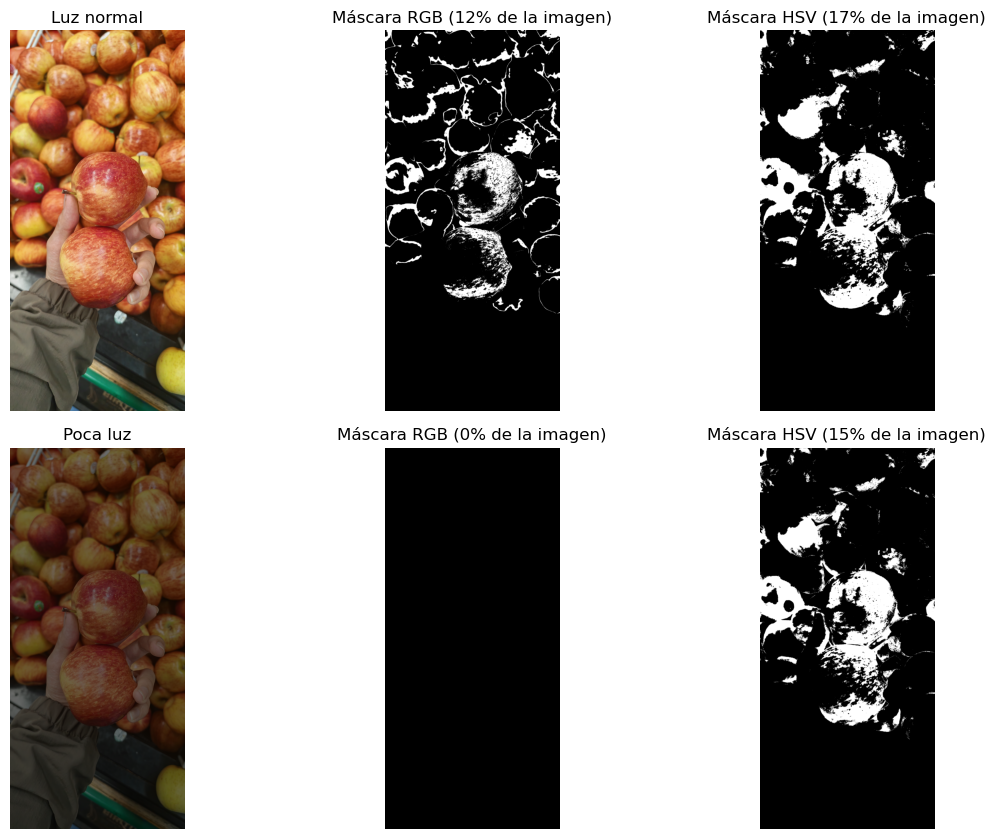

Consistencia entre luz normal y poca luz (IoU, 1 = máscaras idénticas):
  RGB: 0.00
  HSV: 0.86


In [90]:
def mascara_rgb(img):
    R, G, B = [img[..., i].astype(int) for i in range(3)]
    return ((R > 150) & (G < 90) & (B < 90)).astype(np.uint8) * 255


def mascara_hsv(img):
    hsv = cv.cvtColor(img, cv.COLOR_RGB2HSV)
    # El rojo está en ambos extremos del matiz: unimos los dos rangos
    bajo = cv.inRange(hsv, (0, 120, 40), (8, 255, 255))
    alto = cv.inRange(hsv, (170, 120, 40), (179, 255, 255))
    return cv.bitwise_or(bajo, alto)


def iou(a, b):
    a, b = a > 0, b > 0
    return (a & b).sum() / max((a | b).sum(), 1)


resultados = {}
fig, ejes = plt.subplots(2, 3, figsize=(13, 8.5))
for f, (nombre, img) in enumerate([("Luz normal", MANZANA), ("Poca luz", oscura)]):
    m_rgb, m_hsv = mascara_rgb(img), mascara_hsv(img)
    resultados[nombre] = (m_rgb, m_hsv)
    ejes[f, 0].imshow(img)
    ejes[f, 0].set_title(nombre)
    ejes[f, 1].imshow(m_rgb, cmap="gray")
    ejes[f, 1].set_title(f"Máscara RGB ({(m_rgb > 0).mean():.0%} de la imagen)")
    ejes[f, 2].imshow(m_hsv, cmap="gray")
    ejes[f, 2].set_title(f"Máscara HSV ({(m_hsv > 0).mean():.0%} de la imagen)")
for e in ejes.ravel():
    e.axis("off")
plt.tight_layout()
plt.show()

print("Consistencia entre luz normal y poca luz (IoU, 1 = máscaras idénticas):")
print(f"  RGB: {iou(resultados['Luz normal'][0], resultados['Poca luz'][0]):.2f}")
print(f"  HSV: {iou(resultados['Luz normal'][1], resultados['Poca luz'][1]):.2f}")

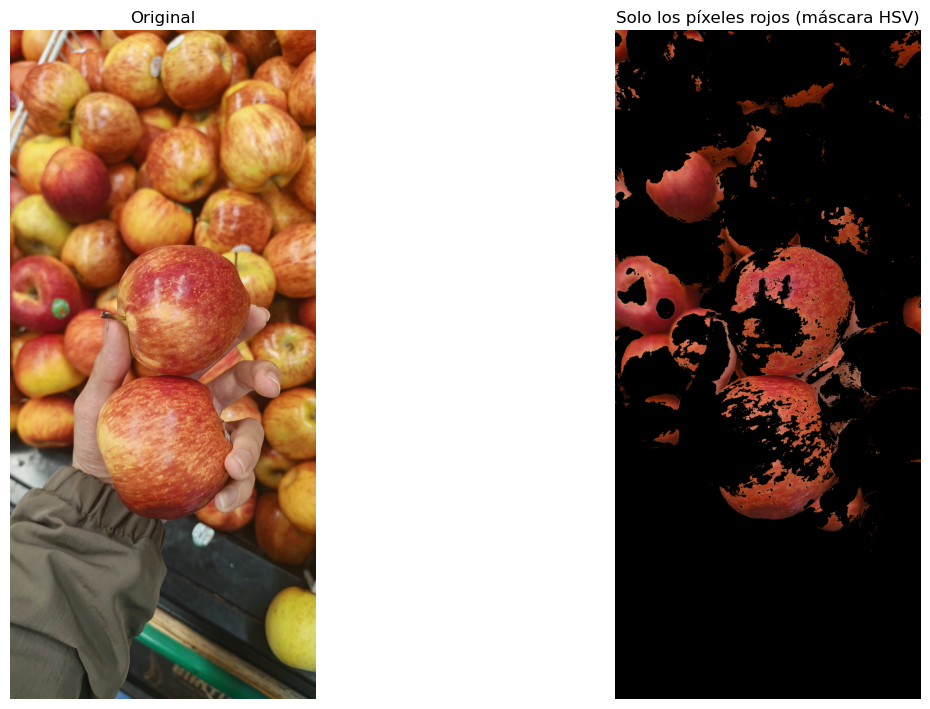

In [94]:
segmentado = cv.bitwise_and(MANZANA, MANZANA, mask=mascara_hsv(MANZANA))
mostrar([MANZANA, segmentado], ["Original", "Solo los píxeles rojos (máscara HSV)"], None, 3, 1,2)

In [95]:
ida_vuelta = cv.cvtColor(cv.cvtColor(MANZANA, cv.COLOR_RGB2HSV), cv.COLOR_HSV2RGB)
print("Error medio RGB → HSV → RGB:", np.abs(ida_vuelta.astype(int) - MANZANA.astype(int)).mean().round(2))

pd.DataFrame([
    ["Gris", 1, "No aplica", "—", "Filtros, bordes, descriptores clásicos", "cv.COLOR_RGB2GRAY"],
    ["Binaria", 1, "No aplica", "—", "Aislar regiones de interés", "cv.threshold"],
    ["RGB", 3, "No", "Baja", "Captura y visualización", "cv.COLOR_BGR2RGB"],
    ["HSV", 3, "Sí", "Alta", "Segmentación por color", "cv.COLOR_RGB2HSV"],
], columns=["Espacio", "Canales", "Separa color y brillo", "Robustez a iluminación", "Uso típico", "Conversión en OpenCV"])

Error medio RGB → HSV → RGB: 0.45


,Espacio,Canales,Separa color y brillo,Robustez a iluminación,Uso típico,Conversión en OpenCV
0,Gris,1,No aplica,—,"Filtros, bordes, descriptores clásicos",cv.COLOR_RGB2GRAY
1,Binaria,1,No aplica,—,Aislar regiones de interés,cv.threshold
2,RGB,3,No,Baja,Captura y visualización,cv.COLOR_BGR2RGB
3,HSV,3,Sí,Alta,Segmentación por color,cv.COLOR_RGB2HSV


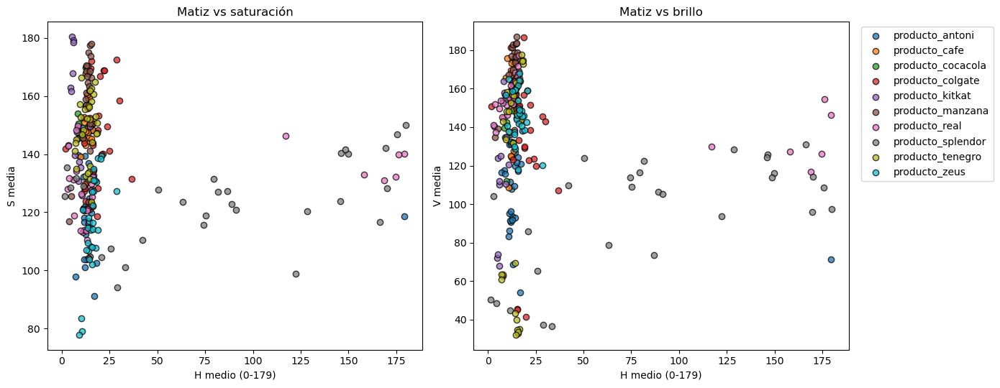

H            S            V      
                   mean   std   mean   std   mean   std
producto                                               
producto_antoni    18.3  30.5  122.8  15.8  107.3  21.6
producto_cafe      13.5   1.8  150.8   6.2  157.1  16.3
producto_cocacola  10.4   2.0  149.6  12.8  135.0  12.7
producto_colgate   18.1   6.6  143.1  18.0  135.6  35.6
producto_kitkat     7.6   2.8  152.2  17.6  123.0  31.0
producto_manzana   13.3   2.8  154.4  22.0  168.8  13.9
producto_real      41.3  62.4  127.9  11.0  152.2  14.4
producto_splendor  85.8  60.5  124.4  14.1   94.8  29.3
producto_tenegro   13.5   3.4  148.4  11.1  115.1  55.1
producto_zeus      15.8   3.7  115.7  16.3  146.5  12.7

In [97]:
def color_medio_hsv(img):
    hsv = cv.cvtColor(cv.resize(img, (128, 128)), cv.COLOR_RGB2HSV).reshape(-1, 3).astype(float)
    hsv_color = hsv[hsv[:, 1] > 60]  # solo píxeles con color (ignora fondo gris/blanco)
    
    # Salvaguarda por si algún empaque es casi todo blanco/negro y no supera S > 60
    if len(hsv_color) == 0:
        hsv_color = hsv
        
    angulo = hsv_color[:, 0] * 2 * np.pi / 180
    h_medio = (np.degrees(np.arctan2(np.sin(angulo).mean(), np.cos(angulo).mean())) % 360) / 2
    return h_medio, hsv_color[:, 1].mean(), hsv_color[:, 2].mean()


# 1. Tus 10 clases (excluimos segmentacion_colgate porque no está en tu tabla de clases)
productos = [
    "producto_antoni",
    "producto_cafe",
    "producto_cocacola",
    "producto_colgate",
    "producto_kitkat",
    "producto_manzana",
    "producto_real",
    "producto_splendor",
    "producto_tenegro",
    "producto_zeus"
]

# 2. Paleta de 10 colores distintos (tab10 de Matplotlib)
colores_graf = plt.cm.tab10.colors

filas = []
for producto in productos:
    # Filtramos usando la columna 'clase' directamente
    rutas = df[(df["split"] == "train") & (df["clase"] == producto)]["ruta"].head(30)
    for r in rutas:
        # Como 'r' ya incluye '..\data\raw\...', la pasamos directo (o usa Path(r))
        h, s, v = color_medio_hsv(leer_rgb(r))
        filas.append({"producto": producto, "H": h, "S": s, "V": v})

caracteristicas = pd.DataFrame(filas)

fig, ejes = plt.subplots(1, 2, figsize=(14, 5.5))
for producto, color in zip(productos, colores_graf):
    sub_df = caracteristicas[caracteristicas["producto"] == producto]
    ejes[0].scatter(sub_df["H"], sub_df["S"], color=color, label=producto, alpha=0.75, edgecolor="k")
    ejes[1].scatter(sub_df["H"], sub_df["V"], color=color, label=producto, alpha=0.75, edgecolor="k")

ejes[0].set(xlabel="H medio (0-179)", ylabel="S media", title="Matiz vs saturación")
ejes[1].set(xlabel="H medio (0-179)", ylabel="V media", title="Matiz vs brillo")
ejes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left")  # leyenda afuera para no tapar puntos
plt.tight_layout()
plt.show()

caracteristicas.groupby("producto")[["H", "S", "V"]].agg(["mean", "std"]).round(1)